<div align="center">

# Université Paris 1 Panthéon-Sorbonne

### M1 MIAGE SBI

### Atelier Python pour Data Science (INF4)

<br>

## Séance 5

#### Mini-projet de synthèse, Data Integration Case Study

<br>

### Groupe G12

#### Ryles AIT-MOHAMMED<br>Aliou DIALLO<br>Meryem BERRAMOU<br>Rita HDIDOU<br>Shirel MARCIANO

<br>

##### Année universitaire 2026-2027

</div>

---

# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

**Group G12**, members Ryles AIT-MOHAMMED, Aliou DIALLO, Meryem BERRAMOU, Rita HDIDOU and Shirel MARCIANO. Individual contributions are listed in the repository README.

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


#### Réglages communs à toute l'analyse
Cette cellule prépare ce qui servira dans toutes les sections. On fixe la période étudiée, du 1er au 28 avril 2025, et on crée le calendrier complet de ces 28 jours.

On calcule aussi une empreinte (SHA-256) de chaque fichier brut et on garde une copie des tableaux bruts. À la fin du notebook, on recalcule ces empreintes pour prouver que les données d'origine n'ont jamais été modifiées.

Enfin, on règle l'affichage des nombres (deux décimales, seulement à l'écran, les calculs gardent toute la précision) et un style commun pour les graphiques. Chaque magasin reçoit une couleur fixe, choisie pour rester lisible par les personnes daltoniennes, et il la garde dans toutes les figures. Les petites fonctions `eur`, `eur_axis` et `add_titles` évitent de répéter le même code pour écrire les montants en euros et les titres des figures.

In [2]:
import hashlib
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

STUDY_START = pd.Timestamp('2025-04-01')
STUDY_END = pd.Timestamp('2025-04-28')

CALENDAR = pd.date_range(STUDY_START, STUDY_END, freq='D')

RAW_FILES = ['case_sales.csv', 'case_stores.csv', 'case_products.csv']
RAW_FINGERPRINTS = {f: hashlib.sha256((DATA_DIR / f).read_bytes()).hexdigest() for f in RAW_FILES}
RAW_SNAPSHOTS = {'sales': sales_raw.copy(deep=True),
                 'stores': stores_raw.copy(deep=True),
                 'products': products_raw.copy(deep=True)}

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

INK, INK_2, INK_MUTED = '#0b0b0b', '#52514e', '#898781'
BAR_COLOR, CONTEXT_COLOR = '#2a78d6', '#a9a8a2'

SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.titlecolor': INK, 'axes.labelcolor': INK_2, 'text.color': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'legend.frameon': False,
})

def eur(x, decimals=0):
    return f'€{x:,.{decimals}f}'

def eur_axis(max_value):
    if max_value >= 5000:
        return FuncFormatter(lambda v, _: '€0' if v == 0 else f'€{v / 1000:,.0f}k')
    return FuncFormatter(lambda v, _: eur(v))

def add_titles(fig, title, subtitle, top_inches=0.95):
    h = fig.get_figheight()
    fig.suptitle(title, x=0.01, y=1 - 0.10 / h, ha='left', va='top', fontsize=12.5, fontweight='bold')
    fig.text(0.01, 1 - 0.40 / h, subtitle, ha='left', va='top', color=INK_2, fontsize=9)
    fig.subplots_adjust(top=1 - top_inches / h)

print('Data folder used', DATA_DIR)
print('Study window from', STUDY_START.date(), 'to', STUDY_END.date(), f'({len(CALENDAR)} days, inclusive)')
print('Outputs written to', OUT_DIR)

Data folder used ../data
Study window from 2025-04-01 to 2025-04-28 (28 days, inclusive)
Outputs written to case_study_outputs


La cellule affiche le dossier de données utilisé, la période étudiée et le dossier où seront enregistrés les résultats. Si l'un de ces éléments était faux, on le verrait tout de suite, avant de lancer l'analyse.

## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

#### Deux outils pour l'audit
Avant de compter quoi que ce soit, on définit deux petites fonctions qu'on réutilisera partout.

- `is_blank` repère une valeur absente ou qui ne contient que des espaces. Une case remplie d'espaces est en pratique aussi vide qu'une case manquante.
- `normalise_id` applique la règle du dictionnaire de données aux identifiants. On enlève les espaces au début et à la fin et on met en majuscules, pour que ` s1 ` et `S1` soient reconnus comme le même magasin.

In [3]:
sources = {'sales': sales_raw, 'stores': stores_raw, 'products': products_raw}

primary_keys = {'sales': 'order_id', 'stores': 'store_id', 'products': 'product_id'}

def is_blank(s):
    return s.fillna('').str.strip().eq('').astype(bool)

def normalise_id(s):
    return s.str.strip().str.upper().replace('', pd.NA)

Cette cellule n'affiche rien. Elle rend seulement ces deux fonctions disponibles pour les cellules suivantes.

#### 1.1 Vue d'ensemble des trois fichiers
On commence par un état des lieux de chaque fichier, sans rien modifier. Pour chacun, on compte les lignes et les colonnes, les cases manquantes, les cases remplies d'espaces, les lignes recopiées à l'identique et les lignes sans clé. On vérifie aussi si une clé se répète encore une fois les copies identiques retirées, car c'est ce qui serait dangereux pour les jointures.

In [4]:
rows = []
for name, frame in sources.items():
    key = primary_keys[name]

    key_after_dedup = normalise_id(frame.drop_duplicates()[key])
    repeated = key_after_dedup[key_after_dedup.notna() & key_after_dedup.duplicated(keep=False)]
    rows.append({
        'source': name,
        'rows': len(frame),
        'columns': frame.shape[1],
        'missing cells (NA)': int(frame.isna().sum().sum()),
        'blank-text cells': int(sum((is_blank(frame[c]) & frame[c].notna()).sum() for c in frame.columns)),
        'rows with at least 1 missing value': int(frame.isna().any(axis=1).sum()),
        'exact duplicate rows (extra copies)': int(frame.duplicated().sum()),
        'expected key': key,
        'rows with missing key': int(normalise_id(frame[key]).isna().sum()),
        'keys still repeated after removing exact duplicates': int(repeated.nunique()),
    })
audit_overview = pd.DataFrame(rows).set_index('source')
print('1.1 Overview of the three sources')
display(audit_overview.T)

1.1 Overview of the three sources


source,sales,stores,products
rows,252,4,7
columns,6,4,3
missing cells (NA),1,0,0
blank-text cells,0,0,0
rows with at least 1 missing value,1,0,0
exact duplicate rows (extra copies),2,0,1
expected key,order_id,store_id,product_id
rows with missing key,0,0,0
keys still repeated after removing exact duplicates,0,0,0


Le fichier des ventes contient 252 lignes, celui des magasins 4 et celui des produits 7. On trouve une seule case manquante (un prix), 2 lignes recopiées à l'identique dans les ventes et 1 dans les produits. Aucune ligne n'a de clé manquante, et aucune clé ne se répète une fois les copies identiques retirées.

#### 1.2 Valeurs manquantes colonne par colonne
Le tableau précédent donne un total. Ici, on regarde colonne par colonne pour savoir exactement où se trouvent les manques, et on compte aussi le nombre de valeurs différentes dans chaque colonne.

In [5]:
rows = []
for name, frame in sources.items():
    for col in frame.columns:
        rows.append({'source': name, 'column': col,
                     'missing (NA)': int(frame[col].isna().sum()),
                     'blank text': int((is_blank(frame[col]) & frame[col].notna()).sum()),
                     'distinct values': int(frame[col].nunique())})
missing_by_column = pd.DataFrame(rows)
print('1.2 Missing values by column')
display(missing_by_column)

1.2 Missing values by column


,source,column,missing (NA),blank text,distinct values
0,sales,order_id,0,0,250
1,sales,date,0,0,30
2,sales,store_id,0,0,6
3,sales,product_id,0,0,8
4,sales,quantity,0,0,6
5,sales,unit_price_eur,1,0,8
6,stores,store_id,0,0,4
7,stores,store_name,0,0,4
8,stores,city,0,0,3
9,stores,store_format,0,0,2


La seule valeur manquante est dans `unit_price_eur`. Toutes les autres colonnes sont complètes. Le nombre de valeurs différentes montre déjà des incohérences d'écriture, par exemple 6 valeurs pour `store_id` alors qu'il n'y a que 4 magasins.

#### 1.3 Les doublons exacts
On affiche toutes les copies des lignes identiques, et pas seulement leur nombre, pour pouvoir vérifier à l'oeil qu'elles sont vraiment identiques sur toutes les colonnes.

In [6]:
for name, frame in sources.items():
    copies = frame[frame.duplicated(keep=False)]
    if len(copies):
        n_copies = int(frame.duplicated().sum())
        print(f'1.3 {name}, {n_copies} extra {"copy" if n_copies == 1 else "copies"} of identical rows')
        display(copies.sort_values(list(frame.columns)))

1.3 sales, 2 extra copies of identical rows


,order_id,date,store_id,product_id,quantity,unit_price_eur
20,O0021,2025-04-10,S1,P01,1,39.90
250,O0021,2025-04-10,S1,P01,1,39.90
90,O0091,2025-04-10,S1,P02,1,19.90
251,O0091,2025-04-10,S1,P02,1,19.90


1.3 products, 1 extra copy of identical rows


,product_id,product_name,category
0,P01,Keyboard,Accessories
6,P01,Keyboard,Accessories


Dans les ventes, les commandes O0021 et O0091 apparaissent chacune deux fois, à l'identique. Dans les produits, la ligne P01 est recopiée une fois. Ce sont de vraies répétitions d'enregistrement, qu'il faudra retirer en les comptant.

#### 1.4 Unicité des clés dans les fichiers de référence
Dans les fichiers des magasins et des produits, chaque identifiant doit apparaître une seule fois. Sinon, une commande trouverait deux magasins lors de la jointure et serait comptée deux fois. On vérifie donc, après avoir normalisé les clés, si des lignes différentes partagent le même identifiant.

In [7]:
for name in ['stores', 'products']:
    key = primary_keys[name]
    dedup = sources[name].drop_duplicates()
    k = normalise_id(dedup[key])
    clash = dedup[k.notna() & k.duplicated(keep=False)]
    print(f'1.4 {name}, {k.nunique()} distinct {key} after trimming and upper-casing, '
          f'{len(clash)} non-identical rows share a {key}')
    if len(clash):
        display(clash.assign(normalised_key=k[clash.index]).sort_values('normalised_key'))

1.4 stores, 4 distinct store_id after trimming and upper-casing, 0 non-identical rows share a store_id
1.4 products, 6 distinct product_id after trimming and upper-casing, 0 non-identical rows share a product_id


Il y a 4 identifiants de magasins et 6 identifiants de produits différents, et aucune ligne différente ne partage le même identifiant. Les fichiers de référence pourront donc être joints sans multiplier les commandes, une fois la copie de P01 retirée.

#### 1.5 Les répétitions normales dans les ventes
Dans les ventes, `store_id` et `product_id` sont des clés étrangères. Il est normal qu'elles se répètent, puisqu'un magasin ou un produit apparaît dans beaucoup de commandes. On le montre pour bien distinguer ces répétitions normales des doublons de la section 1.3.

In [8]:
fk = pd.DataFrame({
    'distinct raw values': [sales_raw[c].nunique() for c in ['store_id', 'product_id']],
    'distinct after trim + upper-case': [normalise_id(sales_raw[c]).nunique() for c in ['store_id', 'product_id']],
    'orders per key (median)': [normalise_id(sales_raw[c]).value_counts().median() for c in ['store_id', 'product_id']],
    'missing': [int(normalise_id(sales_raw[c]).isna().sum()) for c in ['store_id', 'product_id']],
}, index=['store_id', 'product_id'])
print('1.5 Foreign keys in sales (repetition is normal here)')
display(fk)

1.5 Foreign keys in sales (repetition is normal here)


,distinct raw values,distinct after trim + upper-case,orders per key (median),missing
store_id,6,5,50.00,0
product_id,8,7,40.00,0


Une fois les espaces et les minuscules corrigés, on passe de 6 à 5 identifiants de magasins et de 8 à 7 identifiants de produits. Les identifiants en trop (S99 et P99) n'existent pas dans les fichiers de référence, on les retrouvera lors des jointures.

#### 1.6 Les formats à corriger
Avant de nettoyer, on repère les valeurs mal écrites dans les ventes. On cherche les dates qui ne sont pas au format AAAA-MM-JJ, les quantités qui ne sont pas des nombres entiers, les prix écrits avec une virgule et les identifiants avec des espaces ou des minuscules.

In [9]:
txt = {c: sales_raw[c].fillna('').str.strip() for c in ['date', 'quantity', 'unit_price_eur', 'store_id', 'product_id']}
format_issues = pd.Series({
    'date missing or not written YYYY-MM-DD': int((~txt['date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}')).sum()),
    'quantity missing or not written as digits only': int((~txt['quantity'].str.fullmatch(r'\d+')).sum()),
    'unit_price_eur written with a decimal comma': int(txt['unit_price_eur'].str.contains(',', regex=False).sum()),
    'unit_price_eur missing or not a plain number': int((~txt['unit_price_eur'].str.replace(',', '.', regex=False)
                                                         .str.fullmatch(r'-?\d+(\.\d+)?')).sum()),
    'store_id with spaces or lower case': int((sales_raw['store_id'].notna()
                                               & sales_raw['store_id'].ne(normalise_id(sales_raw['store_id'])).fillna(True)).sum()),
    'product_id with spaces or lower case': int((sales_raw['product_id'].notna()
                                                 & sales_raw['product_id'].ne(normalise_id(sales_raw['product_id'])).fillna(True)).sum()),
}, name='raw sales rows')
print('1.6 Formats to convert or check (raw sales rows)')
display(format_issues.to_frame())

1.6 Formats to convert or check (raw sales rows)


,raw sales rows
date missing or not written YYYY-MM-DD,0
quantity missing or not written as digits only,3
unit_price_eur written with a decimal comma,1
unit_price_eur missing or not a plain number,1
store_id with spaces or lower case,1
product_id with spaces or lower case,1


Toutes les dates sont au bon format, mais 3 quantités ne sont pas des nombres entiers, 1 prix utilise une virgule décimale, 1 prix est manquant et 1 identifiant de magasin et 1 identifiant de produit sont mal écrits. C'est la liste de travail de la section 2.

**Your interpretation**

What does one row mean in each source? Which columns connect the sources?

**Unité d'observation.** Dans `case_sales.csv`, une ligne est une commande terminée qui porte sur un seul produit, éventuellement en plusieurs unités. Sa clé est `order_id`. Dans `case_stores.csv`, une ligne est un magasin, de clé `store_id`. Dans `case_products.csv`, une ligne est un produit, de clé `product_id`.

**Colonnes de liaison.** Les ventes se relient aux magasins par `store_id` et aux produits par `product_id`. Avant de joindre, on enlève les espaces et on met ces identifiants en majuscules, sinon ` s1 ` et `S1` ne seraient pas reconnus comme le même magasin. La relation attendue est de type plusieurs pour un (many-to-one), car un magasin ou un produit apparaît dans plusieurs commandes.

**Répétitions normales et répétitions dangereuses.** Dans les ventes, un même `store_id` revient sur toutes les commandes du magasin (S1 apparaît par exemple dans une centaine de lignes). C'est normal, car c'est une clé étrangère. Dans la table des magasins, `store_id` est la clé primaire et doit être unique. S'il y apparaissait deux fois, la jointure recopierait chaque commande de ce magasin en double, ce qui gonflerait le nombre de commandes et le chiffre d'affaires. Et si les deux lignes ne disaient pas la même chose, on ne saurait pas laquelle croire.

**Trois situations à ne pas confondre.** Une donnée manquante est une case vide ou illisible. Il n'y en a qu'une dans les fichiers bruts, un prix absent (tableaux 1.1 et 1.2). Un enregistrement répété est une ligne recopiée à l'identique, qu'on retire en la comptant. On en trouve 2 dans les ventes (commandes O0021 et O0091) et 1 dans les produits (P01), comme le montre le tableau 1.3. Une clé étrangère répétée est normale et ne se corrige pas (tableau 1.5). Enfin, les clés des magasins (4) et des produits (6) sont uniques une fois les doublons exacts retirés (tableau 1.4).

## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

#### 2.1 Retirer les doublons exacts
On travaille sur une copie des ventes, jamais sur le tableau brut. On ajoute le numéro de ligne du fichier CSV pour pouvoir retrouver chaque ligne rejetée dans le fichier d'origine.

Une ligne est un doublon exact si toutes ses colonnes sont identiques à une ligne précédente. On garde la première copie et on compte les autres, comme le demande la règle de qualité.

In [10]:
SALES_COLS = list(sales_raw.columns)

sales_work = sales_raw.copy()
sales_work.insert(0, 'source_line', np.arange(2, len(sales_work) + 2))

exact_dup = sales_work.duplicated(subset=SALES_COLS, keep='first')
sales_exact_duplicates = sales_work[exact_dup]
sales_dedup = sales_work[~exact_dup].reset_index(drop=True)
N_EXACT_DUP = int(exact_dup.sum())
print(f'2.1 Sales, {N_EXACT_DUP} exact duplicate rows removed '
      f'({len(sales_work)} rows before, {len(sales_dedup)} after)')

2.1 Sales, 2 exact duplicate rows removed (252 rows before, 250 after)


Les 2 copies en trop sont retirées, et on passe de 252 à 250 lignes.

#### 2.2 Normaliser les identifiants et convertir les valeurs
On crée la table `sales_clean` à partir des lignes dédoublonnées. Les identifiants sont normalisés, la date est lue au format strict AAAA-MM-JJ et les deux colonnes numériques sont converties en nombres.

La fonction `to_number` accepte la virgule décimale ("179,00" devient 179.0), car c'est la même information écrite autrement. En revanche, tout ce qui reste illisible devient une valeur manquante. On ne devine jamais une valeur, par exemple "two" n'est pas transformé en 2.

In [11]:
def to_number(s):
    txt = s.fillna('').str.strip()

    comma_decimal = (txt.str.contains(',', regex=False) & ~txt.str.contains('.', regex=False)).astype(bool)
    txt = txt.mask(comma_decimal, txt.str.replace(',', '.', regex=False))
    num = pd.to_numeric(txt.astype(object), errors='coerce').astype(float)
    return num.where(np.isfinite(num))

sales_clean = pd.DataFrame({
    'source_line': sales_dedup['source_line'],
    'order_id': normalise_id(sales_dedup['order_id']),

    'date': pd.to_datetime(sales_dedup['date'].fillna('').str.strip().astype(object),
                           format='%Y-%m-%d', errors='coerce'),
    'store_id': normalise_id(sales_dedup['store_id']),
    'product_id': normalise_id(sales_dedup['product_id']),
    'quantity': to_number(sales_dedup['quantity']),
    'unit_price_eur': to_number(sales_dedup['unit_price_eur']),
})

Cette cellule n'affiche rien. Les valeurs converties sont prêtes à être contrôlées à l'étape suivante.

#### 2.3 Un indicateur par motif de rejet
Pour chaque ligne, on crée un indicateur vrai ou faux par problème possible (identifiant manquant, date absente, impossible ou hors période, quantité qui n'est pas un entier positif, prix manquant, illisible ou négatif). On compare avec le texte brut pour distinguer une valeur absente d'une valeur présente mais illisible.

On ajoute deux contrôles sur `order_id`. Une même commande écrite deux fois avec une simple différence d'écriture n'est gardée qu'une fois. Et si un `order_id` apparaît sur des lignes qui se contredisent, toutes ses copies partent en revue, car on ne peut pas savoir laquelle est juste.

In [12]:
raw = sales_dedup
q, p, d = sales_clean['quantity'], sales_clean['unit_price_eur'], sales_clean['date']
flags = pd.DataFrame({
    'missing_order_id': sales_clean['order_id'].isna(),
    'missing_store_id': sales_clean['store_id'].isna(),
    'missing_product_id': sales_clean['product_id'].isna(),
    'missing_date': is_blank(raw['date']),
    'invalid_date': ~is_blank(raw['date']) & d.isna(),
    'date_outside_window': d.notna() & ~d.between(STUDY_START, STUDY_END),
    'missing_quantity': is_blank(raw['quantity']),
    'invalid_quantity': ~is_blank(raw['quantity']) & q.isna(),
    'quantity_not_positive_integer': q.notna() & ((q <= 0) | (q % 1 != 0)),
    'missing_price': is_blank(raw['unit_price_eur']),
    'invalid_price': ~is_blank(raw['unit_price_eur']) & p.isna(),
    'price_not_positive': p.notna() & (p <= 0),
})

NORM_COLS = ['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur']
flags['duplicate_after_normalisation'] = (sales_clean['order_id'].notna()
                                          & sales_clean.duplicated(subset=NORM_COLS, keep='first'))

oid = sales_clean['order_id'].where(~flags['duplicate_after_normalisation'])
flags['repeated_order_id'] = oid.notna() & oid.duplicated(keep=False)
FLAG_COLS = list(flags.columns)

n_issues = flags.sum(axis=1)
review_reasons = flags.apply(lambda row: ', '.join(row.index[row.to_numpy()]), axis=1)
is_valid = n_issues.eq(0)

flag_summary = pd.DataFrame({'rows flagged': flags.sum(),
                             '% of deduplicated rows': 100 * flags.mean()})
print('2.3 Reason flags (one row can carry several flags, so these counts are not additive)')
display(flag_summary)
print('Rejected rows by number of flags')
display(n_issues[~is_valid].value_counts().sort_index().rename_axis('number of flags').to_frame('rejected rows'))

2.3 Reason flags (one row can carry several flags, so these counts are not additive)


,rows flagged,% of deduplicated rows
missing_order_id,0,0.00
missing_store_id,0,0.00
missing_product_id,0,0.00
missing_date,0,0.00
invalid_date,1,0.40
date_outside_window,1,0.40
missing_quantity,0,0.00
invalid_quantity,1,0.40
quantity_not_positive_integer,2,0.80
missing_price,1,0.40


Rejected rows by number of flags


,rejected rows
number of flags,
1,7


Le tableau compte les lignes concernées par chaque motif. Une même ligne pourrait avoir plusieurs motifs, c'est pourquoi on ne doit pas additionner ces nombres. Le second tableau le vérifie, ici chaque ligne rejetée n'a qu'un seul motif.

#### 2.4 Séparer les lignes valides et les lignes à revoir
Une ligne sans aucun motif de rejet va dans `sales_valid`. Les autres vont dans `sales_review`, avec leur texte d'origine, leurs indicateurs et la liste lisible de leurs motifs. On ne supprime donc rien définitivement, chaque rejet reste consultable et justifié.

In [13]:
sales_valid = (sales_clean.loc[is_valid, ['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur']]
               .reset_index(drop=True).copy())

sales_valid['quantity'] = sales_valid['quantity'].astype(int)

sales_review = pd.concat([sales_dedup.loc[~is_valid],
                          flags.loc[~is_valid],
                          n_issues[~is_valid].rename('n_issues'),
                          review_reasons[~is_valid].rename('review_reasons')], axis=1).reset_index(drop=True)

print(f'2.4 sales_review contains {len(sales_review)} rows kept for review (first 15 shown)')
display(sales_review[['source_line'] + SALES_COLS + ['review_reasons']].head(15))

2.4 sales_review contains 7 rows kept for review (first 15 shown)


,source_line,order_id,date,store_id,product_id,quantity,unit_price_eur,review_reasons
0,5,O0004,2025-04-31,S1,P03,1,179.00,invalid_date
1,6,O0005,2025-04-09,S1,P02,two,19.90,invalid_quantity
2,7,O0006,2025-04-04,S1,P06,3,<NA>,missing_price
3,8,O0007,2025-04-12,S1,P06,-1,29.90,quantity_not_positive_integer
4,9,O0008,2025-04-07,S1,P02,2,-19.90,price_not_positive
5,10,O0009,2025-04-13,S1,P02,1.5,19.90,quantity_not_positive_integer
6,13,O0012,2025-05-02,S1,P01,2,39.90,date_outside_window


Sept lignes partent en revue. Il y a une date impossible (31 avril), une date hors période (2 mai), trois quantités non valides ("two", -1 et 1.5), un prix manquant et un prix négatif. Elles concernent toutes le magasin S1.

#### Ce qu'on a réparé et ce qu'on garde tel quel
On compte les lignes valides dont seule l'écriture a été corrigée (virgule décimale, espaces ou minuscules dans les identifiants). Puis on affiche les plus grosses commandes, pour vérifier qu'aucune valeur valide n'a été écartée simplement parce qu'elle est inhabituelle.

In [14]:
repairs = pd.Series({
    'unit_price_eur, decimal comma read as decimal point':
        int((raw['unit_price_eur'].fillna('').str.contains(',', regex=False) & is_valid).sum()),
    'store_id, spaces trimmed or upper-cased':
        int((raw['store_id'].fillna('').ne(sales_clean['store_id'].fillna('')) & is_valid).sum()),
    'product_id, spaces trimmed or upper-cased':
        int((raw['product_id'].fillna('').ne(sales_clean['product_id'].fillna('')) & is_valid).sum()),
    'date not zero-padded but unambiguous (e.g. 2025-4-5)':
        int((~raw['date'].fillna('').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}') & is_valid).sum()),
}, name='valid rows repaired')
print('Formatting repairs on valid rows')
display(repairs.to_frame())

order_value = sales_valid['quantity'] * sales_valid['unit_price_eur']
print('Largest valid orders (kept, nothing indicates an error)')
display(sales_valid.assign(order_value_eur=order_value).nlargest(5, 'order_value_eur'))

Formatting repairs on valid rows


,valid rows repaired
"unit_price_eur, decimal comma read as decimal point",1
"store_id, spaces trimmed or upper-cased",1
"product_id, spaces trimmed or upper-cased",1
date not zero-padded but unambiguous (e.g. 2025-4-5),0


Largest valid orders (kept, nothing indicates an error)


,order_id,date,store_id,product_id,quantity,unit_price_eur,order_value_eur
104,O0112,2025-04-15,S2,P03,3,179.00,537.00
127,O0135,2025-04-18,S2,P03,3,179.00,537.00
141,O0149,2025-04-13,S2,P03,3,179.00,537.00
144,O0152,2025-04-20,S2,P03,3,179.00,537.00
155,O0163,2025-04-05,S2,P03,3,179.00,537.00


Trois lignes valides ont été réparées, une par type de problème d'écriture. Les plus grosses commandes valent 537 € (3 écrans à 179 €). Elles sont inhabituelles mais rien n'indique une erreur, donc on les garde.

#### Contrôle de cohérence des prix
Dans ces données, chaque produit est presque toujours vendu au même prix. On calcule donc le prix habituel de chaque produit (le plus fréquent) et on repère les commandes vendues à un autre prix. On ne fait ce contrôle que pour les produits qui ont un prix habituel net, c'est-à-dire vendu à ce prix dans au moins 80 % des commandes.

Ces commandes ne sont pas supprimées, car rien ne prouve qu'il s'agit d'erreurs. On les signale et on calcule l'écart en euros, pour mesurer leur effet sur les totaux en section 4.

In [15]:
price_stats = sales_valid.groupby('product_id')['unit_price_eur'].agg(
    usual_price=lambda x: x.mode().iloc[0],
    share_at_usual_price=lambda x: (x == x.mode().iloc[0]).mean())
usual_price = sales_valid['product_id'].map(price_stats['usual_price'])

has_usual_price = sales_valid['product_id'].map(price_stats['share_at_usual_price']) >= 0.8
unusual = (has_usual_price & ~np.isclose(sales_valid['unit_price_eur'], usual_price)).to_numpy()
unusual_prices = sales_valid[unusual].assign(
    usual_price_eur=usual_price[unusual],

    excess_eur=((sales_valid['unit_price_eur'] - usual_price) * sales_valid['quantity'])[unusual])
print(f'Valid orders sold at a price different from the usual price of their product ({len(unusual_prices)} orders, '
      'kept and flagged)')
display(unusual_prices)

Valid orders sold at a price different from the usual price of their product (2 orders, kept and flagged)


,order_id,date,store_id,product_id,quantity,unit_price_eur,usual_price_eur,excess_eur
1,O0002,2025-04-14,S1,P02,2,39.90,19.90,40.00
2,O0003,2025-04-14,S1,P04,1,179.00,59.90,119.10


Deux commandes sont concernées. O0002 vend une souris à 39,90 € au lieu de 19,90 €, et O0003 vend un casque à 179 € (le prix d'un écran) au lieu de 59,90 €. L'écart total est de 159,10 €.

#### 2.5 Nettoyer les fichiers de référence
On applique la même logique aux magasins et aux produits. On retire les doublons exacts, on normalise les clés, on nettoie les textes et on uniformise l'écriture des étiquettes (par exemple "small" et "Small" deviennent la même étiquette).

Si une clé se répète encore avec des informations différentes, on ne garde jamais simplement la première ligne. Si les lignes se contredisent sur l'identité (le nom ou la ville), la clé pourrait désigner deux choses différentes, elle est donc mise de côté. Si elles ne diffèrent que sur une étiquette (le format ou la catégorie), on garde la ligne une seule fois et l'étiquette contestée devient inconnue.

In [16]:
def harmonise_labels(s):
    s = s.str.strip().str.replace(r'\s+', ' ', regex=True).replace('', pd.NA)
    lower = s.str.lower()
    spelling = s.dropna().groupby(lower.dropna()).agg(lambda x: x.value_counts().sort_index().idxmax())
    return lower.map(spelling).astype('string')

QUARANTINED = 'key quarantined, its orders go to integration_review'
KEPT_UNRESOLVED = 'kept once, disputed attribute set to missing (not guessed)'

def clean_reference(raw_table, key, identity_cols, label_cols, text_cols, note_col):
    work = raw_table.drop_duplicates().copy()
    audit = {'rows in': len(raw_table), 'exact duplicates removed': len(raw_table) - len(work)}
    work[key] = normalise_id(work[key])
    for c in text_cols:
        work[c] = work[c].str.strip().str.replace(r'\s+', ' ', regex=True).replace('', pd.NA)
    relabelled = 0
    for c in label_cols:
        new = harmonise_labels(work[c])
        relabelled += int((work[c].fillna('').str.strip() != new.fillna('')).sum())
        work[c] = new
    audit['label spellings harmonised'] = relabelled
    same_after_tidy = work.duplicated()
    audit['rows identical after tidying (collapsed)'] = int(same_after_tidy.sum())
    work = work[~same_after_tidy].reset_index(drop=True)

    missing_key = work[key].isna()
    repeated = work[key].notna() & work[key].duplicated(keep=False)
    disputed = {k: [c for c in work.columns if c != key and g[c].nunique(dropna=False) > 1]
                for k, g in work[repeated].groupby(key)}
    identity_conflict = [k for k, cols in disputed.items() if set(cols) & set(identity_cols)]
    label_conflict = [k for k in disputed if k not in identity_conflict]

    review = work[missing_key | repeated].copy()
    review['attributes_in_conflict'] = review[key].map(lambda k: ', '.join(disputed.get(k, []))).fillna('')
    review['action'] = np.where(review[key].isna(), 'excluded, no key to join on',
                                np.where(review[key].isin(identity_conflict), QUARANTINED, KEPT_UNRESOLVED))

    clean = work[~missing_key & ~repeated].copy()
    clean[note_col] = ''
    resolved = []
    for k in label_conflict:
        grp = work[work[key].eq(k)]
        row = {c: (pd.NA if c in disputed[k] else grp[c].iloc[0]) for c in work.columns}
        row[note_col] = ', '.join(disputed[k])
        resolved.append(row)
    if resolved:
        clean = pd.concat([clean, pd.DataFrame(resolved)], ignore_index=True)
    clean = clean.astype({c: 'string' for c in work.columns}).sort_values(key).reset_index(drop=True)
    audit.update({'rows with missing key': int(missing_key.sum()),
                  'keys quarantined (identity conflict)': len(identity_conflict),
                  'keys kept with a disputed label set to missing': len(label_conflict),
                  'rows in clean table': len(clean)})
    return clean, review.reset_index(drop=True), audit

stores_clean, stores_review, stores_audit = clean_reference(
    stores_raw, 'store_id', identity_cols=['store_name', 'city'], label_cols=['city', 'store_format'],
    text_cols=['store_name'], note_col='store_unresolved')
products_clean, products_review, products_audit = clean_reference(
    products_raw, 'product_id', identity_cols=['product_name'], label_cols=['category'],
    text_cols=['product_name'], note_col='product_unresolved')
reference_audit = pd.DataFrame({'stores': stores_audit, 'products': products_audit})
print('2.5 Reference tables')
display(reference_audit)

for name, review in [('stores', stores_review), ('products', products_review)]:
    if len(review):
        print(f'{name}, rows that needed investigation')
        display(review)

2.5 Reference tables


,stores,products
rows in,4,7
exact duplicates removed,0,1
label spellings harmonised,0,0
rows identical after tidying (collapsed),0,0
rows with missing key,0,0
keys quarantined (identity conflict),0,0
keys kept with a disputed label set to missing,0,0
rows in clean table,4,6


Les 4 magasins sont propres. Pour les produits, la copie de P01 est retirée et il reste 6 produits. Aucune clé en conflit n'a été trouvée, donc aucune ligne n'a eu besoin d'être mise de côté.

#### 2.6 Vérifications finales du nettoyage
On vérifie automatiquement que les clés sont uniques et non manquantes dans les tables propres, et que chaque ligne du fichier d'entrée est retrouvée quelque part. Si une seule vérification était fausse, le notebook s'arrêterait avec une erreur au lieu de continuer avec des données incohérentes.

In [17]:
assert stores_clean['store_id'].notna().all() and stores_clean['store_id'].is_unique
assert products_clean['product_id'].notna().all() and products_clean['product_id'].is_unique
assert sales_valid['order_id'].notna().all() and sales_valid['order_id'].is_unique

assert len(sales_raw) == N_EXACT_DUP + len(sales_review) + len(sales_valid)

cleaning_check = pd.Series({'input rows (case_sales.csv)': len(sales_raw),
                            'exact duplicates removed': N_EXACT_DUP,
                            'invalid or repeated rows kept in sales_review': len(sales_review),
                            'valid rows (sales_valid)': len(sales_valid)}, name='rows')
print('2.6 Checkpoint OK, input rows = exact duplicates removed + rows kept for review + valid rows')
display(cleaning_check.to_frame())
print('Keys checked, store_id and product_id are unique in the references and order_id is unique in sales_valid')

2.6 Checkpoint OK, input rows = exact duplicates removed + rows kept for review + valid rows


,rows
input rows (case_sales.csv),252
exact duplicates removed,2
invalid or repeated rows kept in sales_review,7
valid rows (sales_valid),243


Keys checked, store_id and product_id are unique in the references and order_id is unique in sales_valid


Le compte est juste. Les 252 lignes d'entrée se répartissent en 2 doublons exacts retirés, 7 lignes en revue et 243 lignes valides.

**Your interpretation**

Which records did you exclude, repair or keep? Why?

**Doublons exacts retirés.** Deux lignes de ventes étaient des copies exactes d'une autre ligne (commandes O0021 et O0091, identiques sur toutes les colonnes). Nous avons retiré ces 2 copies en les comptant, car une même commande ne doit être comptée qu'une fois. Dans la table des produits, la ligne P01 était aussi en double exact et a été retirée.

**Lignes réparées et gardées.** Trois lignes avaient seulement un problème d'écriture. Le prix "179,00" utilisait une virgule décimale, et les identifiants " s1 " et " p02 " avaient des espaces et des minuscules. L'information était juste et seule sa forme changeait, donc nous avons corrigé la représentation sans inventer de valeur.

**Lignes exclues et gardées pour revue.** Sept lignes vont dans `sales_review`, avec leur texte d'origine et le motif du rejet :

- une date impossible (2025-04-31) et une date hors de la période d'étude (2025-05-02) ;
- trois quantités qui ne sont pas des entiers positifs ("two", -1 et 1.5) ;
- un prix manquant et un prix négatif (-19.90).

Nous ne remplaçons aucune de ces valeurs, car deviner la bonne date, la bonne quantité ou le bon prix reviendrait à inventer des données. Ces 7 lignes concernent toutes Paris Centre (S1), ce qui est une limite à garder en tête pour ce magasin.

**Valeurs inhabituelles gardées.** Les plus grosses commandes valent 537 € (3 écrans à 179 €). Elles sont inhabituelles mais valides, donc nous les gardons. Deux commandes ont un prix différent du prix habituel de leur produit. La commande O0002 vend une souris à 39,90 € au lieu de 19,90 €, et la commande O0003 vend un casque à 179,00 €, le prix d'un écran, au lieu de 59,90 €. Rien ne prouve qu'il s'agit d'erreurs, donc nous les gardons en les signalant, et le test 4.8 montre que leur écart (159,10 € au total) ne change pas le classement.

**Contrôle.** 252 lignes en entrée = 2 doublons exacts retirés + 7 lignes en revue + 243 lignes valides. Les clés `store_id` et `product_id` sont uniques et non manquantes dans les tables de référence (4 magasins et 6 produits), et chaque `order_id` valide est unique.

## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

#### 3.1 Jointure avec les magasins
On ajoute aux commandes valides les informations du magasin. On utilise une jointure à gauche, qui garde toutes les commandes, même celles dont le magasin est inconnu.

L'option `validate="many_to_one"` vérifie qu'un magasin n'apparaît qu'une fois dans la table des magasins, sinon pandas s'arrête au lieu de dupliquer des commandes. L'indicateur `store_match` dit pour chaque commande si son magasin a été trouvé. On vérifie enfin que la jointure garde exactement le même nombre de lignes.

In [18]:
quarantined_stores = stores_review.loc[stores_review['action'].eq(QUARANTINED), 'store_id']
quarantined_products = products_review.loc[products_review['action'].eq(QUARANTINED), 'product_id']

orders_stores = sales_valid.merge(stores_clean, on='store_id', how='left',
                                  validate='many_to_one', indicator='store_match')

assert len(orders_stores) == len(sales_valid), 'the store join changed the number of rows'
print(f'3.1 Store join, {len(sales_valid)} rows before and {len(orders_stores)} rows after, no row was multiplied')
print(orders_stores['store_match'].value_counts().to_string(), '\n')

def unmatched_keys(frame, key, indicator, quarantined):
    out = (frame.loc[frame[indicator].eq('left_only'), key]
           .value_counts().rename_axis(key).reset_index(name='orders'))
    out['reason'] = np.where(out[key].isin(quarantined), 'quarantined, conflicting rows in reference file',
                             'absent from reference file')
    return out

display(unmatched_keys(orders_stores, 'store_id', 'store_match', quarantined_stores))

3.1 Store join, 243 rows before and 243 rows after, no row was multiplied
store_match
both          242
left_only       1
right_only      0 



,store_id,orders,reason
0,S99,1,absent from reference file


On a 243 lignes avant et après la jointure. 242 commandes ont trouvé leur magasin, et une seule ne l'a pas trouvé, celle du magasin S99, absent du fichier des magasins.

#### 3.2 Jointure avec les produits
On fait la même chose avec les produits, avec les mêmes contrôles. On utilise un autre nom d'indicateur (`product_match`) pour ne pas écraser celui de la jointure précédente.

In [19]:
orders_full = orders_stores.merge(products_clean, on='product_id', how='left',
                                  validate='many_to_one', indicator='product_match')
assert len(orders_full) == len(orders_stores), 'the product join changed the number of rows'
print(f'3.2 Product join, {len(orders_stores)} rows before and {len(orders_full)} rows after, no row was multiplied')
print(orders_full['product_match'].value_counts().to_string(), '\n')
display(unmatched_keys(orders_full, 'product_id', 'product_match', quarantined_products))

3.2 Product join, 243 rows before and 243 rows after, no row was multiplied
product_match
both          242
left_only       1
right_only      0 



,product_id,orders,reason
0,P99,1,absent from reference file


Le nombre de lignes reste 243. Une seule commande ne trouve pas son produit, celle du produit P99, absent du fichier des produits.

#### 3.3 Séparer les commandes analysées et les commandes à revoir
On ne garde dans `analysis` que les commandes rattachées à la fois à un magasin et à un produit. Les autres vont dans `integration_review`, avec la raison du problème écrite en clair.

On calcule quand même leur montant, mais on ne l'attribue à aucun magasin. Surtout, une commande dont le produit est inconnu n'est jamais comptée comme 0 €.

In [20]:
store_ok = orders_full['store_match'].eq('both').to_numpy()
product_ok = orders_full['product_match'].eq('both').to_numpy()

store_issue = np.where(store_ok, '', np.where(orders_full['store_id'].isin(quarantined_stores),
                       'store_id quarantined (conflicting reference rows)', 'store_id not in case_stores.csv'))
product_issue = np.where(product_ok, '', np.where(orders_full['product_id'].isin(quarantined_products),
                         'product_id quarantined (conflicting reference rows)', 'product_id not in case_products.csv'))

orders_full['store_matched'] = store_ok
orders_full['product_matched'] = product_ok
orders_full['integration_issue'] = [' and '.join(t for t in pair if t) for pair in zip(store_issue, product_issue)]

integration_review = (orders_full.loc[~(store_ok & product_ok)]
                      .drop(columns=['store_match', 'product_match']).reset_index(drop=True).copy())

integration_review['order_value_eur'] = integration_review['quantity'] * integration_review['unit_price_eur']

analysis = (orders_full.loc[store_ok & product_ok]
            .drop(columns=['store_match', 'product_match', 'store_matched', 'product_matched', 'integration_issue'])
            .reset_index(drop=True).copy())

assert len(analysis) + len(integration_review) == len(sales_valid)
assert analysis['order_id'].is_unique
print(f'3.3 analysis has {len(analysis)} orders matched to both references, '
      f'integration_review has {len(integration_review)} orders')
display(integration_review[['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur',
                            'order_value_eur', 'integration_issue']])

3.3 analysis has 241 orders matched to both references, integration_review has 2 orders


,order_id,date,store_id,product_id,quantity,unit_price_eur,order_value_eur,integration_issue
0,O0010,2025-04-04,S99,P06,3,29.90,89.70,store_id not in case_stores.csv
1,O0011,2025-04-20,S1,P99,1,39.90,39.90,product_id not in case_products.csv


L'analyse porte sur 241 commandes. Deux commandes valides sont mises de côté, O0010 (magasin S99, 89,70 €) et O0011 (produit P99, 39,90 €).

#### 3.4 Tableau de réconciliation
Ce tableau suit les lignes du fichier brut jusqu'à la population analysée, étape par étape, avec le montant en jeu à chaque étape. Les nombres négatifs sont les lignes retirées. Les contrôles automatiques vérifient que chaque étape tombe juste.

In [21]:
value = lambda df: float((df['quantity'] * df['unit_price_eur']).sum())
minus = lambda x: -x if x else 0.0
only_store_missing = integration_review[~integration_review['store_matched'] & integration_review['product_matched']]
only_product_missing = integration_review[integration_review['store_matched'] & ~integration_review['product_matched']]
both_missing = integration_review[~integration_review['store_matched'] & ~integration_review['product_matched']]

reconciliation = pd.DataFrame([
    ('Raw rows in case_sales.csv', len(sales_raw), np.nan),
    ('Exact duplicate rows removed', -N_EXACT_DUP, np.nan),
    ('Rows after removing exact duplicates', len(sales_dedup), np.nan),
    ('Invalid or repeated rows kept in sales_review', -len(sales_review), np.nan),
    ('Valid orders (sales_valid)', len(sales_valid), value(sales_valid)),
    ('Valid orders with store unknown or quarantined (product matched)', -len(only_store_missing),
     minus(value(only_store_missing))),
    ('Valid orders with product unknown or quarantined (store matched)', -len(only_product_missing),
     minus(value(only_product_missing))),
    ('Valid orders with neither reference matched', -len(both_missing), minus(value(both_missing))),
    ('Orders in the analysis (matched to both references)', len(analysis), value(analysis)),
], columns=['step', 'rows', 'order_value_eur'])

assert len(sales_raw) - N_EXACT_DUP == len(sales_dedup)
assert len(sales_dedup) - len(sales_review) == len(sales_valid)
assert len(sales_valid) - len(integration_review) == len(analysis)
assert np.isclose(value(sales_valid) - integration_review['order_value_eur'].sum(), value(analysis))
print('3.4 Reconciliation from raw input to the analytical population (all checks passed)')
display(reconciliation)

N_EXCLUDED_ORDERS = len(sales_review) + len(integration_review)
print(f'The analysis keeps {len(analysis)} of {len(sales_dedup)} distinct records '
      f'({100 * len(analysis) / len(sales_dedup):.1f}%). It excludes {N_EXCLUDED_ORDERS} records, '
      f'{len(sales_review)} invalid or repeated and {len(integration_review)} valid but unmatched '
      f'(worth {eur(integration_review["order_value_eur"].sum())}). '
      f'In addition, {N_EXACT_DUP} exact duplicate copies were removed beforehand.')

3.4 Reconciliation from raw input to the analytical population (all checks passed)


,step,rows,order_value_eur
0,Raw rows in case_sales.csv,252,NaN
1,Exact duplicate rows removed,-2,NaN
2,Rows after removing exact duplicates,250,NaN
3,Invalid or repeated rows kept in sales_review,-7,NaN
4,Valid orders (sales_valid),243,"27,836.40"
5,Valid orders with store unknown or quarantined (product matched),-1,-89.70
6,Valid orders with product unknown or quarantined (store matched),-1,-39.90
7,Valid orders with neither reference matched,0,0.00
8,Orders in the analysis (matched to both references),241,"27,706.80"


The analysis keeps 241 of 250 distinct records (96.4%). It excludes 9 records, 7 invalid or repeated and 2 valid but unmatched (worth €130). In addition, 2 exact duplicate copies were removed beforehand.


On part de 252 lignes et on arrive à 241 commandes analysées, pour un chiffre d'affaires de 27 706,80 € HT. L'analyse garde 96,4 % des 250 enregistrements distincts.

**Your interpretation**

Why use left joins first, even though the analysis ultimately uses matched orders?

La jointure à gauche garde toutes les commandes valides, y compris celles dont le magasin ou le produit est inconnu. Grâce aux indicateurs `store_match` puis `product_match`, on voit exactement quelles commandes n'ont pas trouvé leur référence, et pourquoi. Une jointure interne les aurait supprimées sans laisser de trace. On n'aurait alors ni leur nombre ni leur montant, et le contrôle « même nombre de lignes avant et après la jointure » serait impossible.

L'option `validate="many_to_one"` ajoute une sécurité. Si une clé était encore en double dans une table de référence, pandas arrêterait le calcul au lieu de multiplier les commandes en silence. Les `assert` vérifient en plus que chaque jointure garde exactement le même nombre de lignes, ici 243 avant et 243 après chacune des deux jointures.

Ensuite seulement, on ne garde dans `analysis` que les commandes rattachées à la fois à un magasin et à un produit. Deux commandes valides sont dans `integration_review`, la commande O0010 (magasin S99 absent du fichier des magasins, 89,70 €) et la commande O0011 (produit P99 absent du fichier des produits, 39,90 €). Leur montant n'est attribué à aucun magasin, et une commande dont le produit est inconnu n'est jamais comptée comme 0 €. Au total, l'analyse exclut 9 enregistrements distincts sur 250 (7 invalides et 2 non rattachés) et garde 241 commandes, soit 27 706,80 € HT, comme le montre le tableau de réconciliation.

## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

#### 4.1 Chiffre d'affaires de chaque commande
Le chiffre d'affaires d'une commande est la quantité multipliée par le prix unitaire. On ne l'arrondit pas, l'arrondi se fera seulement à l'affichage.

On prépare aussi une étiquette de catégorie pour les regroupements. Une catégorie inconnue ou contestée serait affichée telle quelle, jamais supprimée ni devinée. On écrit enfin une phrase qui décrit la population étudiée, réutilisée sous les titres des figures.

In [22]:
analysis['revenue_eur'] = analysis['quantity'] * analysis['unit_price_eur']

category_disputed = analysis['product_unresolved'].fillna('').str.contains('category').to_numpy(dtype=bool)
analysis['category_label'] = np.where(category_disputed, '(category disputed in reference)',
                                      analysis['category'].fillna('(category missing in reference)'))
TOTAL_REVENUE = analysis['revenue_eur'].sum()
N_ORDERS = len(analysis)

POPULATION = (f'{N_ORDERS} valid orders matched to store and product references, '
              f'extract of 1 to 28 April 2025, revenue in EUR excl. VAT')
print('Population analysed is', POPULATION)
print(f'Total revenue in the analysis is {eur(TOTAL_REVENUE, 2)}')

Population analysed is 241 valid orders matched to store and product references, extract of 1 to 28 April 2025, revenue in EUR excl. VAT
Total revenue in the analysis is €27,706.80


Le chiffre d'affaires total des 241 commandes analysées est de 27 706,80 € HT.

#### 4.2 Tableau par magasin
Pour chaque magasin, on calcule le nombre de commandes, le nombre d'unités, le chiffre d'affaires total, la part du total, la moyenne et la médiane par commande et le nombre de jours présents dans l'extrait.

La moyenne par commande est le chiffre d'affaires total divisé par le nombre de commandes, et non par le nombre d'unités, car `quantity` compte des unités. On ajoute deux indicateurs qui aideront à expliquer les écarts, les unités par commande et le chiffre d'affaires par unité. On regroupe d'abord par identifiant, puis on ajoute le nom du magasin, pour qu'une information manquante ne puisse pas faire disparaître un magasin.

In [23]:
store_kpis = (analysis.groupby('store_id')
              .agg(order_count=('order_id', 'size'),
                   total_units=('quantity', 'sum'),
                   total_revenue_eur=('revenue_eur', 'sum'),
                   median_revenue_per_order_eur=('revenue_eur', 'median'),
                   days_with_orders=('date', 'nunique'))
              .reset_index())

store_kpis['mean_revenue_per_order_eur'] = store_kpis['total_revenue_eur'] / store_kpis['order_count']
store_kpis['revenue_share_pct'] = 100 * store_kpis['total_revenue_eur'] / TOTAL_REVENUE
store_kpis['units_per_order'] = store_kpis['total_units'] / store_kpis['order_count']
store_kpis['revenue_per_unit_eur'] = store_kpis['total_revenue_eur'] / store_kpis['total_units']

store_summary = (stores_clean.merge(store_kpis, on='store_id', how='inner', validate='one_to_one')
                 .sort_values('total_revenue_eur', ascending=False).reset_index(drop=True))

store_summary['rank_total_revenue'] = store_summary['total_revenue_eur'].rank(ascending=False, method='min').astype(int)
store_summary['rank_mean_order_revenue'] = (store_summary['mean_revenue_per_order_eur']
                                            .rank(ascending=False, method='min').astype(int))
store_summary = store_summary[['store_id', 'store_name', 'city', 'store_format',
                               'order_count', 'total_units', 'total_revenue_eur', 'revenue_share_pct',
                               'mean_revenue_per_order_eur', 'median_revenue_per_order_eur',
                               'units_per_order', 'revenue_per_unit_eur', 'days_with_orders',
                               'rank_total_revenue', 'rank_mean_order_revenue']]
print('\n4.2 store_summary (sorted by total revenue)')
display(store_summary)

absent = sorted(set(stores_clean['store_id']) - set(store_summary['store_id']))
if absent:
    print('Stores in the reference with no order in the analysis (not evidence of zero sales)', absent)


4.2 store_summary (sorted by total revenue)


,store_id,store_name,city,store_format,order_count,total_units,total_revenue_eur,revenue_share_pct,mean_revenue_per_order_eur,median_revenue_per_order_eur,units_per_order,revenue_per_unit_eur,days_with_orders,rank_total_revenue,rank_mean_order_revenue
0,S2,Paris Est,Paris,Large,70,116,"10,528.90",38.00,150.41,79.80,1.66,90.77,25,1,2
1,S1,Paris Centre,Paris,Small,91,155,"6,482.90",23.40,71.24,39.90,1.70,41.83,27,2,4
2,S4,Lille Centre,Lille,Large,30,51,"5,712.50",20.62,190.42,158.50,1.70,112.01,20,3,1
3,S3,Lyon Centre,Lyon,Small,50,86,"4,982.50",17.98,99.65,64.45,1.72,57.94,22,4,3


Paris Est (S2) a le plus gros total (10 528,90 €), Paris Centre (S1) le plus de commandes (91) et Lille Centre (S4) la moyenne et la médiane par commande les plus élevées (190,42 € et 158,50 €). Les deux dernières colonnes donnent le rang de chaque magasin selon le total et selon la moyenne.

#### 4.3 Tableau par catégorie de produit
On fait le même résumé par catégorie, pour voir quels types de produits pèsent le plus dans le chiffre d'affaires.

In [24]:
category_summary = (analysis.groupby('category_label')
                    .agg(order_count=('order_id', 'size'),
                         total_units=('quantity', 'sum'),
                         total_revenue_eur=('revenue_eur', 'sum'),
                         median_revenue_per_order_eur=('revenue_eur', 'median'))
                    .reset_index().rename(columns={'category_label': 'category'}))
category_summary['mean_revenue_per_order_eur'] = category_summary['total_revenue_eur'] / category_summary['order_count']
category_summary['revenue_share_pct'] = 100 * category_summary['total_revenue_eur'] / TOTAL_REVENUE
category_summary = (category_summary.sort_values('total_revenue_eur', ascending=False).reset_index(drop=True)
                    [['category', 'order_count', 'total_units', 'total_revenue_eur', 'revenue_share_pct',
                      'mean_revenue_per_order_eur', 'median_revenue_per_order_eur']])
print('4.3 category_summary')
display(category_summary)

4.3 category_summary


,category,order_count,total_units,total_revenue_eur,revenue_share_pct,mean_revenue_per_order_eur,median_revenue_per_order_eur
0,Screens,45,81,"14,499.00",52.33,322.20,358.00
1,Accessories,133,224,"6,427.60",23.20,48.33,39.90
2,Video,32,54,"3,726.00",13.45,116.44,103.50
3,Audio,31,49,"3,054.20",11.02,98.52,59.90


Les écrans représentent 52 % du chiffre d'affaires avec seulement 45 commandes. À l'inverse, les accessoires font 133 commandes mais seulement 23 % du chiffre d'affaires.

#### 4.4 Chiffre d'affaires par jour et par magasin
On calcule le chiffre d'affaires de chaque magasin pour chaque jour, puis on l'aligne sur le calendrier complet des 28 jours.

Un jour sans commande dans l'extrait reste vide (NaN) et n'est pas remplacé par 0. L'extrait n'est pas complet, donc un jour absent ne prouve ni une absence de ventes ni une fermeture du magasin.

In [25]:
daily_store_revenue = (analysis.groupby(['date', 'store_id'])
                       .agg(orders=('order_id', 'size'), revenue_eur=('revenue_eur', 'sum'))
                       .reset_index())
daily_revenue = (daily_store_revenue.pivot(index='date', columns='store_id', values='revenue_eur')
                 .reindex(CALENDAR))
daily_revenue.index.name = 'date'

coverage = pd.DataFrame({'days with recorded orders': daily_revenue.notna().sum(),
                         'days absent from the extract': daily_revenue.isna().sum()})
print('4.4 Daily revenue table in EUR (NaN means no record in the extract, not zero)')
display(daily_revenue.round(0))
display(coverage.T)

4.4 Daily revenue table in EUR (NaN means no record in the extract, not zero)


store_id,S1,S2,S3,S4
date,,,,
2025-04-01,70.00,676.00,239.00,259.00
2025-04-02,200.00,309.00,568.00,358.00
2025-04-03,269.00,358.00,30.00,606.00
2025-04-04,419.00,577.00,140.00,358.00
2025-04-05,269.00,955.00,267.00,168.00
2025-04-06,80.00,397.00,478.00,120.00
2025-04-07,149.00,299.00,NaN,40.00
2025-04-08,446.00,854.00,676.00,179.00
2025-04-09,70.00,NaN,NaN,209.00


store_id,S1,S2,S3,S4
days with recorded orders,27,25,22,20
days absent from the extract,1,3,6,8


Les cases NaN sont les jours absents de l'extrait. Le second tableau les compte, Lille Centre manque 8 jours sur 28 alors que Paris Centre n'en manque qu'un seul.

#### 4.5 Vérifier que les totaux concordent
Les tableaux par magasin, par catégorie et par jour doivent tous redonner le même total que le calcul commande par commande. On le vérifie automatiquement, pour être sûr qu'aucune commande n'a été perdue ou comptée deux fois dans un regroupement.

In [26]:
checks = pd.DataFrame({
    'revenue_eur': [TOTAL_REVENUE, store_summary['total_revenue_eur'].sum(),
                    category_summary['total_revenue_eur'].sum(), np.nansum(daily_revenue.to_numpy())],
    'orders': [N_ORDERS, store_summary['order_count'].sum(), category_summary['order_count'].sum(),
               daily_store_revenue['orders'].sum()],
}, index=['order level (analysis)', 'store_summary', 'category_summary', 'daily table'])
assert np.allclose(checks['revenue_eur'], TOTAL_REVENUE) and (checks['orders'] == N_ORDERS).all()
assert np.allclose(store_summary['order_count'] * store_summary['mean_revenue_per_order_eur'],
                   store_summary['total_revenue_eur'])
print('4.5 All totals reconcile with the order-level revenue (checks passed)')
display(checks)

4.5 All totals reconcile with the order-level revenue (checks passed)


,revenue_eur,orders
order level (analysis),"27,706.80",241
store_summary,"27,706.80",241
category_summary,"27,706.80",241
daily table,"27,706.80",241


Les quatre lignes donnent le même total, 27 706,80 € pour 241 commandes.

#### 4.6 Le même magasin est-il en tête sur le total et sur la moyenne ?
On compare le magasin en tête sur le total avec celui en tête sur la moyenne et sur la médiane par commande.

Pour comprendre les écarts, on décompose le total. Le total est égal au nombre de commandes multiplié par la moyenne par commande, et la moyenne est égale aux unités par commande multipliées par le prix moyen par unité. On ajoute le chiffre d'affaires par jour présent dans l'extrait, pour tenir compte de la couverture. Ce n'est pas un chiffre par jour d'ouverture, que l'on ne connaît pas.

In [27]:
lead_total = store_summary.loc[store_summary['total_revenue_eur'].idxmax()]
lead_mean = store_summary.loc[store_summary['mean_revenue_per_order_eur'].idxmax()]
lead_median = store_summary.loc[store_summary['median_revenue_per_order_eur'].idxmax()]
for label, row, col in [('total revenue', lead_total, 'total_revenue_eur'),
                        ('mean revenue per order', lead_mean, 'mean_revenue_per_order_eur'),
                        ('median revenue per order', lead_median, 'median_revenue_per_order_eur')]:
    print(f'Highest {label} is {row["store_name"]} ({row["store_id"]}) with {eur(row[col], 2)} '
          f'from {row["order_count"]} orders')
print('Same store leads total and mean revenue?', 'yes' if lead_total['store_id'] == lead_mean['store_id'] else 'no')

decomposition = store_summary[['store_id', 'store_name', 'order_count', 'mean_revenue_per_order_eur',
                               'total_revenue_eur', 'units_per_order', 'revenue_per_unit_eur', 'days_with_orders']].copy()

decomposition['revenue_per_recorded_day_eur'] = decomposition['total_revenue_eur'] / decomposition['days_with_orders']
print('\nDecomposition, total revenue = number of orders x mean order revenue, '
      'and mean order revenue = units per order x revenue per unit')
display(decomposition)

Highest total revenue is Paris Est (S2) with €10,528.90 from 70 orders
Highest mean revenue per order is Lille Centre (S4) with €190.42 from 30 orders
Highest median revenue per order is Lille Centre (S4) with €158.50 from 30 orders
Same store leads total and mean revenue? no

Decomposition, total revenue = number of orders x mean order revenue, and mean order revenue = units per order x revenue per unit


,store_id,store_name,order_count,mean_revenue_per_order_eur,total_revenue_eur,units_per_order,revenue_per_unit_eur,days_with_orders,revenue_per_recorded_day_eur
0,S2,Paris Est,70,150.41,"10,528.90",1.66,90.77,25,421.16
1,S1,Paris Centre,91,71.24,"6,482.90",1.70,41.83,27,240.11
2,S4,Lille Centre,30,190.42,"5,712.50",1.70,112.01,20,285.62
3,S3,Lyon Centre,50,99.65,"4,982.50",1.72,57.94,22,226.48


Ce n'est pas le même magasin. Paris Est est en tête sur le total, Lille Centre sur la moyenne et la médiane. Les unités par commande sont presque identiques partout (environ 1,7), donc l'écart de moyenne vient du prix des produits vendus (112 € par unité à Lille Centre contre 42 € à Paris Centre). Rapporté aux jours présents, Paris Est reste devant avec 421 € par jour.

#### 4.7 Le mix produit de chaque magasin
Pour vérifier cette explication, on calcule la part de chaque catégorie dans le chiffre d'affaires de chaque magasin. Le dénominateur est le chiffre d'affaires total du magasin, donc chaque ligne fait 100 %.

In [28]:
store_order = store_summary['store_id'].tolist()
mix_revenue = analysis.pivot_table(index='store_id', columns='category_label', values='revenue_eur',
                                   aggfunc='sum', fill_value=0).reindex(store_order)
mix_share = 100 * mix_revenue.div(mix_revenue.sum(axis=1), axis=0)
mix_share = mix_share[category_summary['category'].tolist()]
mix_share.columns.name = 'category'
print("4.7 Share of each store's revenue by category in % (each row sums to 100)")
display(mix_share.round(1))

4.7 Share of each store's revenue by category in % (each row sums to 100)


category,Screens,Accessories,Video,Audio
store_id,,,,
S2,66.30,11.80,10.50,11.40
S1,16.60,49.60,18.10,15.70
S4,78.30,7.30,13.30,1.00
S3,39.50,31.00,13.80,15.60


Les écrans représentent 78 % du chiffre d'affaires de Lille Centre et 66 % de celui de Paris Est, contre 17 % à Paris Centre, qui vend surtout des accessoires. Le mix produit explique donc une grande partie des écarts de moyenne.

#### 4.8 Le classement résiste-t-il aux données exclues ?
On teste si le classement par total pourrait changer à cause des données exclues ou douteuses. On ajoute d'abord à leur magasin les commandes valides exclues dont le magasin est connu, puis on retire l'écart dû aux prix inhabituels.

Enfin, on prend le cas le plus défavorable. On suppose que tout ce qui a été exclu irait au deuxième magasin, en comptant chaque ligne rejetée comme la plus grosse commande observée (537 €).

In [29]:
sensitivity = store_summary[['store_id', 'store_name', 'total_revenue_eur', 'rank_total_revenue']].copy()

known_store_value = (integration_review[integration_review['store_matched']]
                     .groupby('store_id')['order_value_eur'].sum())
sensitivity['plus_excluded_orders_eur'] = sensitivity['store_id'].map(known_store_value).fillna(0.0)

price_excess = (unusual_prices[unusual_prices['order_id'].isin(analysis['order_id'])]
                .groupby('store_id')['excess_eur'].sum())
sensitivity['minus_unusual_price_excess_eur'] = sensitivity['store_id'].map(price_excess).fillna(0.0)
sensitivity['high_total_eur'] = sensitivity['total_revenue_eur'] + sensitivity['plus_excluded_orders_eur']
sensitivity['low_total_eur'] = sensitivity['total_revenue_eur'] - sensitivity['minus_unusual_price_excess_eur']
sensitivity['rank_if_high'] = sensitivity['high_total_eur'].rank(ascending=False, method='min').astype(int)
sensitivity['rank_if_low'] = sensitivity['low_total_eur'].rank(ascending=False, method='min').astype(int)
print('4.8 Sensitivity of the ranking by total revenue')
display(sensitivity)

max_order_value = analysis['revenue_eur'].max()
excluded_valid_value = integration_review['order_value_eur'].sum()
max_at_stake = len(sales_review) * max_order_value + excluded_valid_value
gap = store_summary['total_revenue_eur'].iloc[0] - store_summary['total_revenue_eur'].iloc[1]
print(f'Gap between the first and the second store is {eur(gap, 2)}.')
print(f'All excluded rows together are worth at most {eur(max_at_stake, 2)} '
      f'({len(sales_review)} rejected rows counted at {eur(max_order_value, 2)} each, '
      f'plus {eur(excluded_valid_value, 2)} of valid but unmatched orders).')
if gap > max_at_stake:
    print('Even in this worst case, the store with the highest total revenue stays the same.')
else:
    print('In this worst case the leader could change, so the ranking must be read with caution.')

4.8 Sensitivity of the ranking by total revenue


,store_id,store_name,total_revenue_eur,rank_total_revenue,plus_excluded_orders_eur,minus_unusual_price_excess_eur,high_total_eur,low_total_eur,rank_if_high,rank_if_low
0,S2,Paris Est,"10,528.90",1,0.00,0.00,"10,528.90","10,528.90",1,1
1,S1,Paris Centre,"6,482.90",2,39.90,159.10,"6,522.80","6,323.80",2,2
2,S4,Lille Centre,"5,712.50",3,0.00,0.00,"5,712.50","5,712.50",3,3
3,S3,Lyon Centre,"4,982.50",4,0.00,0.00,"4,982.50","4,982.50",4,4


Gap between the first and the second store is €4,046.00.
All excluded rows together are worth at most €3,888.60 (7 rejected rows counted at €537.00 each, plus €129.60 of valid but unmatched orders).
Even in this worst case, the store with the highest total revenue stays the same.


Le classement ne change dans aucun cas. L'écart entre Paris Est et Paris Centre (4 046 €) reste plus grand que tout ce qui a été exclu, même dans le pire cas (3 888,60 €).

**Your interpretation**

Does the same store lead for total and mean revenue? What can explain a difference?

Non. Paris Est (S2) a le chiffre d'affaires total le plus élevé (10 528,90 € HT, soit 38 % du total, pour 70 commandes), mais c'est Lille Centre (S4) qui a la moyenne par commande la plus élevée (190,42 €) et aussi la médiane la plus élevée (158,50 €). Lille Centre n'est pourtant que troisième sur le total, avec 30 commandes.

**Rôle du nombre de commandes.** Le total est égal au nombre de commandes multiplié par la moyenne par commande. Paris Est combine beaucoup de commandes et une moyenne élevée (150,41 €), ce qui lui donne le premier total. Paris Centre (S1) a le plus de commandes (91) mais la moyenne la plus faible (71,24 €), d'où sa deuxième place. Lille Centre a la meilleure moyenne mais trois fois moins de commandes que Paris Centre, d'où sa troisième place.

**Rôle du mix produit.** Le nombre d'unités par commande est presque le même dans les quatre magasins (entre 1,66 et 1,72), donc les écarts de moyenne viennent surtout du prix des produits vendus. Le chiffre d'affaires par unité vendue va de 41,83 € à Paris Centre à 112,01 € à Lille Centre. Les écrans (179 € l'unité) représentent 50 % des commandes et 78 % du chiffre d'affaires de Lille Centre, contre 3 % des commandes et 17 % du chiffre d'affaires de Paris Centre, où 78 % des commandes portent sur des accessoires vendus moins de 40 €. Tous magasins confondus, les écrans font 52 % du chiffre d'affaires avec seulement 45 commandes sur 241.

**Moyenne et médiane.** Dans chaque magasin, la moyenne est au-dessus de la médiane, car quelques grosses commandes d'écrans tirent la moyenne vers le haut. La médiane décrit mieux la commande typique, et elle confirme l'écart entre Lille Centre (158,50 €) et Paris Centre (39,90 €).

**Couverture.** Les magasins n'apparaissent pas le même nombre de jours dans l'extrait (27 jours pour Paris Centre, 25 pour Paris Est, 22 pour Lyon Centre et 20 pour Lille Centre), donc une partie des écarts de total peut venir de la couverture. Rapporté aux jours présents dans l'extrait, Paris Est reste devant avec 421 € par jour enregistré, contre 286 € pour Lille Centre. Les totaux se réconcilient avec le niveau commande (27 706,80 € pour 241 commandes dans les trois tableaux), et le test 4.8 montre que le magasin en tête ne change pas, même si toutes les lignes exclues allaient au deuxième magasin. Ces indicateurs décrivent du chiffre d'affaires, pas une rentabilité ni une productivité.

## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

#### Figure 1, chiffre d'affaires total par magasin
**Question.** Quels magasins font le plus de chiffre d'affaires dans l'extrait, et avec combien de commandes ?<br>
**Unité d'observation.** Une commande valide rattachée à un magasin et à un produit connus.<br>
**Agrégation.** Pour chaque magasin, la somme du chiffre d'affaires et le nombre de commandes.

On utilise des barres horizontales, triées du plus grand au plus petit, pour que les noms des magasins restent lisibles. Le nombre de commandes est sur un second graphique à côté, avec les magasins dans le même ordre, plutôt que sur un double axe qui mélangerait deux échelles. Chaque barre porte sa valeur et sa part du total.

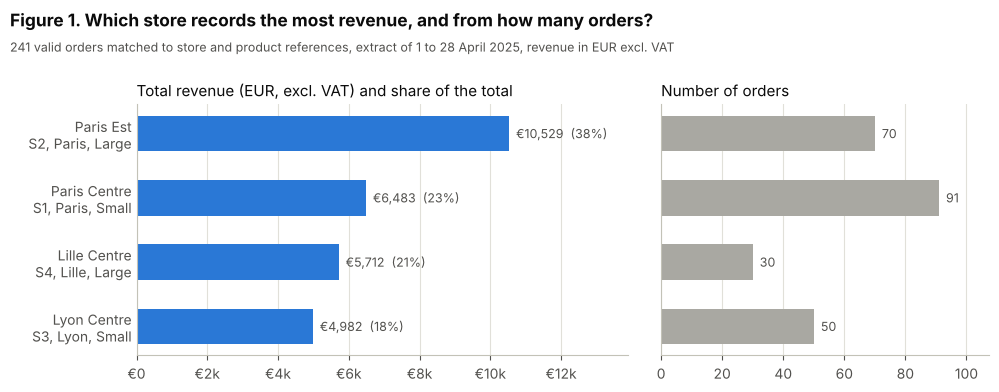

In [30]:
STORE_NAME = dict(zip(store_summary['store_id'], store_summary['store_name'].fillna(store_summary['store_id'])))
STORE_LABEL = {s: f'{STORE_NAME[s]} ({s})' for s in store_summary['store_id']}
assert len(store_summary) <= len(SERIES_COLORS), 'more stores than distinct colours, use small multiples'

STORE_COLOR = dict(zip(sorted(store_summary['store_id']), SERIES_COLORS))

f1 = store_summary.iloc[::-1]
ylabels = [f'{STORE_NAME[s]}\n{s}, {c}, {fmt}' for s, c, fmt in
           zip(f1['store_id'], f1['city'].fillna('city unknown'), f1['store_format'].fillna('format unknown'))]
y = np.arange(len(f1))

fig1, (ax_rev, ax_n) = plt.subplots(1, 2, figsize=(11, 1.0 + 0.75 * len(f1)), sharey=True,
                                    gridspec_kw={'width_ratios': [3, 2], 'wspace': 0.08})
ax_rev.barh(y, f1['total_revenue_eur'], height=0.55, color=BAR_COLOR)
ax_n.barh(y, f1['order_count'], height=0.55, color=CONTEXT_COLOR)

for yi, (v, share) in enumerate(zip(f1['total_revenue_eur'], f1['revenue_share_pct'])):
    ax_rev.text(v, yi, f'  {eur(v)}  ({share:.0f}%)', va='center', ha='left', color=INK_2, fontsize=9)
for yi, n in enumerate(f1['order_count']):
    ax_n.text(n, yi, f'  {n}', va='center', ha='left', color=INK_2, fontsize=9)

ax_rev.set_yticks(y)
ax_rev.set_yticklabels(ylabels)
ax_rev.set_title('Total revenue (EUR, excl. VAT) and share of the total', loc='left')
ax_n.set_title('Number of orders', loc='left')
ax_rev.xaxis.set_major_formatter(eur_axis(f1['total_revenue_eur'].max()))
ax_rev.set_xlim(0, f1['total_revenue_eur'].max() * 1.32)
ax_n.set_xlim(0, f1['order_count'].max() * 1.18)
for ax in (ax_rev, ax_n):
    ax.grid(axis='x')
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0)
add_titles(fig1, 'Figure 1. Which store records the most revenue, and from how many orders?',
           POPULATION, top_inches=1.05)
plt.show()

À gauche, la longueur des barres donne le chiffre d'affaires, à droite le nombre de commandes. Comparer les deux côtés montre tout de suite que le classement n'est pas le même.

**Your interpretation**

State the question, unit and aggregation; then interpret the chart.

**Question.** Quel magasin enregistre le plus de chiffre d'affaires dans l'extrait, et avec combien de commandes ?

**Unité d'observation.** Une commande valide rattachée à un magasin et à un produit connus (241 commandes).

**Agrégation.** Pour chaque magasin, la somme du chiffre d'affaires HT (à gauche) et le nombre de commandes (à droite). Les deux mesures sont sur deux graphiques séparés, avec les magasins dans le même ordre, pour ne pas mélanger deux échelles sur un même axe.

**Interprétation.** Paris Est (S2) arrive nettement en tête avec 10 529 € HT, soit 38 % du chiffre d'affaires analysé, alors qu'il traite moins de commandes que Paris Centre (70 contre 91). Le classement par chiffre d'affaires n'est donc pas celui du nombre de commandes, ce qui montre qu'un gros total peut venir du nombre de commandes ou de leur valeur.

**Limite.** Le total dépend du nombre de jours présents dans l'extrait (27 pour Paris Centre, 20 seulement pour Lille Centre) et ne tient compte ni des coûts ni de la fréquentation, donc ce n'est ni un classement de rentabilité ni un classement de productivité.

#### Figure 2, distribution du chiffre d'affaires par commande
**Question.** Combien vaut une commande typique dans chaque magasin, et à quel point les montants varient-ils ?<br>
**Unité d'observation.** Une commande, sans agrégation.

On utilise une boîte à moustaches par magasin, dans le même ordre que la figure 1. Elle montre la médiane, la moitié centrale des commandes et les commandes atypiques. On ajoute la moyenne avec un losange pour la comparer à la médiane, et le nombre de commandes sous chaque boîte. Les commandes atypiques sont gardées, car rien ne montre qu'elles sont fausses.

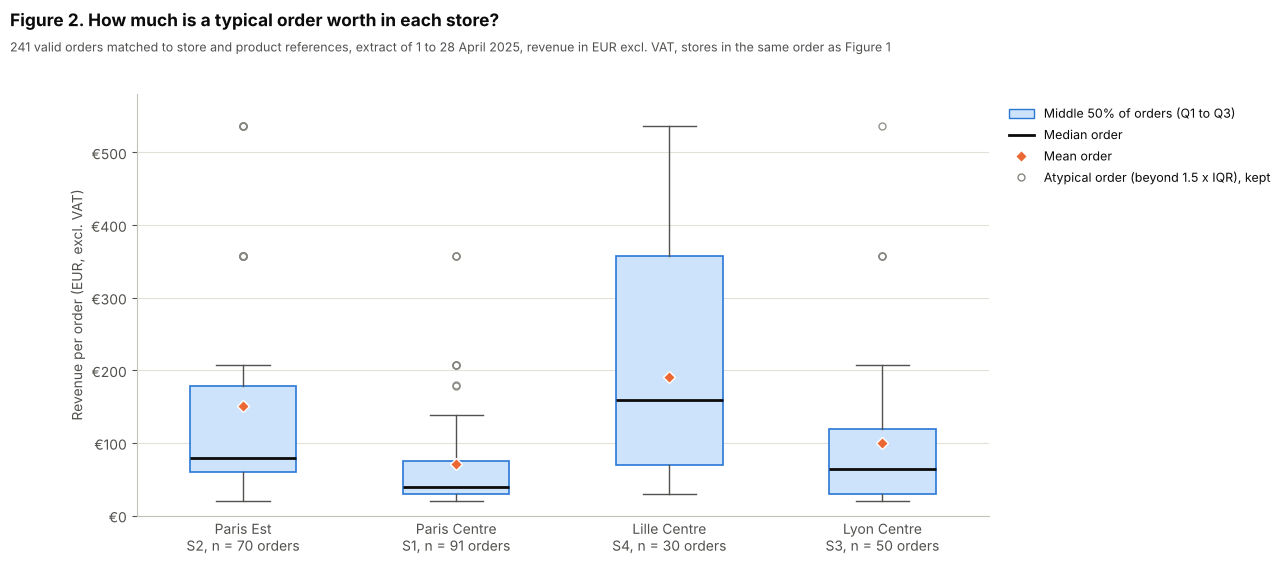

Order revenue by store in EUR


,orders,mean,std,min,25%,median,75%,max
store_id,,,,,,,,
S2,70.00,150.41,146.56,19.90,59.75,79.80,179.00,537.00
S1,91.00,71.24,70.01,19.90,29.90,39.90,74.40,358.00
S4,30.00,190.42,136.89,29.90,69.00,158.50,358.00,537.00
S3,50.00,99.65,105.36,19.90,29.90,64.45,119.77,537.00


In [31]:
import textwrap

groups = [analysis.loc[analysis['store_id'].eq(s), 'revenue_eur'].to_numpy() for s in store_order]

fig2, ax = plt.subplots(figsize=(11, 5.8))
ax.boxplot(groups, patch_artist=True, widths=0.5, showmeans=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=BAR_COLOR, linewidth=1.2),
           medianprops=dict(color=INK, linewidth=2),
           meanprops=dict(marker='D', markersize=6, markerfacecolor='#eb6834', markeredgecolor='white'),
           whiskerprops=dict(color=INK_2, linewidth=1), capprops=dict(color=INK_2, linewidth=1),
           flierprops=dict(marker='o', markersize=5, markerfacecolor='none',
                           markeredgecolor=INK_MUTED, alpha=0.9))

ax.set_xticks(np.arange(1, len(store_order) + 1))
ax.set_xticklabels(['\n'.join(textwrap.wrap(STORE_NAME[s], 18)) + f'\n{s}, n = {len(g)} orders'
                    for s, g in zip(store_order, groups)])

ax.set_ylim(0, analysis['revenue_eur'].max() * 1.08)
ax.set_ylabel('Revenue per order (EUR, excl. VAT)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: eur(v)))
ax.grid(axis='y')
ax.set_axisbelow(True)
ax.tick_params(axis='x', length=0)

legend_items = [Patch(facecolor='#cde2fb', edgecolor=BAR_COLOR, label='Middle 50% of orders (Q1 to Q3)'),
                Line2D([0], [0], color=INK, linewidth=2, label='Median order'),
                Line2D([0], [0], marker='D', linestyle='none', markersize=6, markerfacecolor='#eb6834',
                       markeredgecolor='white', label='Mean order'),
                Line2D([0], [0], marker='o', linestyle='none', markersize=5, markerfacecolor='none',
                       markeredgecolor=INK_MUTED, label='Atypical order (beyond 1.5 x IQR), kept')]
ax.legend(handles=legend_items, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
add_titles(fig2, 'Figure 2. How much is a typical order worth in each store?',
           POPULATION + ', stores in the same order as Figure 1')
plt.show()

print('Order revenue by store in EUR')
display(analysis.groupby('store_id')['revenue_eur'].describe().loc[store_order]
        .rename(columns={'count': 'orders', '50%': 'median'}))

La boîte contient la moitié centrale des commandes, le trait noir est la médiane, le losange la moyenne et les ronds les commandes atypiques. Le tableau sous la figure donne les mêmes valeurs en chiffres.

**Your interpretation**

State the question and observation unit; describe spread and a limitation.

**Question.** Combien vaut une commande typique dans chaque magasin, et à quel point les montants varient-ils ?

**Unité d'observation.** Une commande, sans agrégation, chaque commande compte une fois dans la distribution de son magasin. Le nombre de commandes (n) est affiché sous chaque boîte.

**Interprétation.** Lille Centre (S4) a la commande typique la plus élevée, avec une médiane de 158,50 € et la moitié centrale de ses commandes entre 69 € et 358 €, alors que la moitié centrale des commandes de Paris Centre (S1) se situe entre 29,90 € et 74,40 €, avec une médiane de 39,90 €. Dans les quatre magasins, la moyenne (losange) est au-dessus de la médiane, car quelques grosses commandes d'écrans, jusqu'à 537 €, tirent la moyenne vers le haut.

**Valeurs atypiques.** Les ronds sont des commandes atypiques (au-delà de 1,5 fois l'écart interquartile). Nous les gardons, car ce sont des achats d'écrans tout à fait possibles et rien n'indique qu'ils sont faux.

**Limite.** Les montants ne prennent que peu de valeurs différentes (6 prix et 1 à 3 unités par commande), donc plusieurs commandes identiques se superposent sur un même rond (Paris Est a par exemple 5 commandes à 537 €). De plus, Lille Centre ne compte que 30 commandes, donc ses quartiles sont moins stables que ceux de Paris Centre (91 commandes).

#### Figure 3, chiffre d'affaires jour par jour
**Question.** Comment le chiffre d'affaires enregistré évolue-t-il chaque jour dans chaque magasin, et quels jours manquent ?<br>
**Unité d'observation.** Un magasin un jour donné.<br>
**Agrégation.** La somme du chiffre d'affaires des commandes de ce magasin ce jour-là.

On fait un petit graphique par magasin plutôt qu'un seul, car quatre courbes qui se croisent seraient illisibles. Les quatre graphiques partagent le même calendrier et la même échelle pour rester comparables, et chaque magasin garde sa couleur. Un jour sans commande reste vide, la ligne s'interrompt au lieu de descendre à 0. Les bandes grises marquent les week-ends.

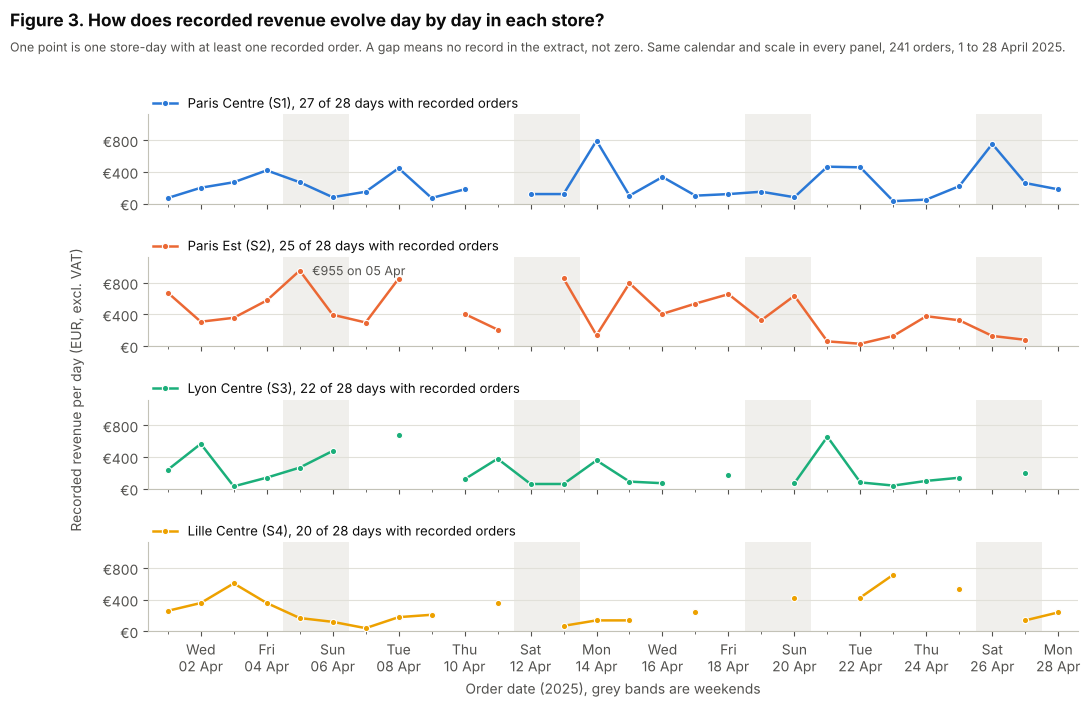

In [32]:
from matplotlib.ticker import MaxNLocator

panel_stores = sorted(daily_revenue.columns)
weekend = [d for d in CALENDAR if d.dayofweek >= 5]

y_top = np.nanmax(daily_revenue.to_numpy()) * 1.18
peak_store = daily_revenue.max().idxmax()
peak_day = daily_revenue[peak_store].idxmax()

fig3, axes = plt.subplots(len(panel_stores), 1, figsize=(12, 1.3 * len(panel_stores) + 1.9),
                          sharex=True, sharey=True, gridspec_kw={'hspace': 0.6})
axes = np.atleast_1d(axes)
for ax, s in zip(axes, panel_stores):

    for d in weekend:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color='#f0efec', linewidth=0, zorder=0)

    series = daily_revenue[s]
    ax.plot(series.index, series.to_numpy(), color=STORE_COLOR[s], linewidth=1.8, marker='o', markersize=4.5,
            markeredgecolor='white', markeredgewidth=0.8, zorder=3)

    key = Line2D([0], [0], color=STORE_COLOR[s], linewidth=1.8, marker='o', markersize=4.5,
                 markeredgecolor='white', markeredgewidth=0.8)
    ax.legend([key], [f'{STORE_LABEL[s]}, {int(series.notna().sum())} of {len(CALENDAR)} days with recorded orders'],
              loc='lower left', bbox_to_anchor=(0, 0.98), borderaxespad=0, handlelength=1.8, fontsize=9.5)

    if s == peak_store:
        ax.annotate(f'{eur(series[peak_day])} on {peak_day:%d %b}', (peak_day, series[peak_day]),
                    xytext=(9, 0), textcoords='offset points', va='center', fontsize=9, color=INK_2)
    ax.set_ylim(0, y_top)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.yaxis.set_major_formatter(eur_axis(y_top))
    ax.grid(axis='y')
    ax.set_axisbelow(True)

axes[-1].set_xlim(STUDY_START - pd.Timedelta(days=0.6), STUDY_END + pd.Timedelta(days=0.6))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[-1].xaxis.set_minor_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%a\n%d %b'))
axes[-1].set_xlabel('Order date (2025), grey bands are weekends')
fig3.text(0.065, 0.45, 'Recorded revenue per day (EUR, excl. VAT)', rotation=90, ha='center', va='center',
          color=INK_2, fontsize=10)
add_titles(fig3, 'Figure 3. How does recorded revenue evolve day by day in each store?',
           'One point is one store-day with at least one recorded order. A gap means no record in the extract, '
           f'not zero. Same calendar and scale in every panel, {N_ORDERS} orders, 1 to 28 April 2025.',
           top_inches=1.15)
plt.show()

Chaque point est un jour avec au moins une commande enregistrée, et chaque trou un jour absent de l'extrait. Seul le jour record est étiqueté, pour ne pas surcharger la figure.

**Your interpretation**

What does one point represent? How did you treat missing dates?

**Question.** Comment le chiffre d'affaires enregistré évolue-t-il jour après jour dans chaque magasin, et quels jours manquent dans l'extrait ?

**Unité d'observation et agrégation.** Un point représente un couple magasin et jour, c'est-à-dire la somme du chiffre d'affaires HT des commandes d'un magasin un jour donné, quand l'extrait contient au moins une commande ce jour-là. Les quatre panneaux utilisent le même calendrier (du 1er au 28 avril 2025) et la même échelle, et chaque magasin garde sa couleur.

**Jours manquants.** Un jour sans commande dans l'extrait est laissé vide et la ligne s'interrompt. Nous ne mettons pas 0, car l'extrait n'est pas complet et un jour absent ne prouve ni une absence de ventes ni une fermeture. Lille Centre a 8 jours sans enregistrement, Lyon Centre 6, Paris Est 3 et Paris Centre 1.

**Interprétation.** Les montants journaliers varient beaucoup, de 29,90 € à 954,90 € (Paris Est le samedi 5 avril), et Paris Est est le magasin le plus élevé 14 jours sur 28. On ne voit ni tendance commune sur le mois ni effet du week-end identique pour tous les magasins.

**Limite.** Avec 1 à 6 commandes par magasin et par jour, une seule commande d'écrans suffit à créer un pic, donc ces variations ne doivent pas être lues comme une tendance.

**Pourquoi trois figures.** La figure 1 compare des totaux par magasin, la figure 2 montre la distribution des commandes une par une et la figure 3 montre l'évolution dans le temps et la couverture de l'extrait. Elles répondent à trois questions différentes (combien au total, combien par commande, quand et avec quelle couverture), et c'est leur lecture ensemble qui montre qu'un gros total ne suffit pas à désigner le magasin le plus performant.

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

**Your interpretation**

Write your final decision brief here.

**Note au responsable.**

L'affirmation selon laquelle le magasin au plus gros chiffre d'affaires total serait le plus performant n'est pas confirmée par cet extrait, car le classement change selon l'indicateur choisi. Sur les 241 commandes valides du 1er au 28 avril 2025 rattachées à un magasin et à un produit connus, Paris Est (S2) réalise le plus gros chiffre d'affaires total, avec 10 529 € HT, soit 38 % du total. Pourtant, Lille Centre (S4) a le montant par commande le plus élevé, avec une moyenne de 190,42 € et une médiane de 158,50 € par commande, contre 150,41 € et 79,80 € à Paris Est, tandis que Paris Centre (S1) traite le plus de commandes (91) pour la moyenne la plus faible (71,24 €). Le total mesure donc un volume de ventes plutôt qu'une performance, et le chiffre d'affaires n'est pas un bénéfice, puisque les coûts, le personnel, les horaires et la fréquentation ne sont pas connus. Notre hypothèse est que le mix produit explique une grande partie de ces écarts, car les écrans pèsent 78 % du chiffre d'affaires de Lille Centre et 66 % de celui de Paris Est, contre 17 % à Paris Centre. Côté qualité des données, 9 enregistrements sur 250 ont été exclus (7 lignes invalides, toutes à Paris Centre, et 2 commandes dont le magasin ou le produit est inconnu), sans que cela change le magasin en tête. Côté couverture, l'extrait n'est pas complet et ne couvre pas les magasins de la même façon (27 jours sur 28 pour Paris Centre, 20 seulement pour Lille Centre), donc un total plus faible peut simplement refléter moins de jours enregistrés. Avant de copier l'approche d'un magasin, nous recommandons d'obtenir l'extraction complète d'avril pour les quatre magasins, avec les jours d'ouverture, les coûts, les marges, les effectifs et la fréquentation, afin de comparer les magasins à périmètre égal.

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

#### Section 7, export des résultats et vérifications
On enregistre les tableaux demandés en CSV (sans la colonne d'index de pandas) et les trois figures en PNG dans le dossier `case_study_outputs`. Les montants sont arrondis à 2 décimales seulement dans les fichiers exportés. On exporte aussi quelques fichiers complémentaires utiles comme preuves.

Puis on fait les dernières vérifications. On recalcule les empreintes des fichiers bruts et on les compare à celles du début, on vérifie que les tableaux bruts n'ont pas changé, que les jointures n'ont pas multiplié les lignes et que les totaux concordent.

In [33]:
money = lambda df: df.round({c: 2 for c in df.columns if c.endswith('_eur') or c.endswith('_pct')
                             or c in ('units_per_order',)})
exports = {
    'store_summary.csv': money(store_summary),
    'category_summary.csv': money(category_summary),
    'reconciliation.csv': money(reconciliation),
    'sales_review.csv': sales_review,
    'integration_review.csv': money(integration_review.assign(date=integration_review['date'].dt.strftime('%Y-%m-%d'))),

    'unusual_price_orders.csv': money(unusual_prices.assign(date=unusual_prices['date'].dt.strftime('%Y-%m-%d'))),
    'daily_store_revenue.csv': money(daily_store_revenue.assign(date=daily_store_revenue['date'].dt.strftime('%Y-%m-%d'))),
    'reference_review.csv': pd.concat([stores_review.assign(table='stores'),
                                       products_review.assign(table='products')], ignore_index=True),
}

for name, table in exports.items():
    table.to_csv(OUT_DIR / name, index=False)

figures = {'fig1_total_revenue_by_store.png': fig1,
           'fig2_order_revenue_distribution.png': fig2,
           'fig3_daily_revenue_by_store.png': fig3}
for name, fig in figures.items():
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches='tight', facecolor='white')

assert {f: hashlib.sha256((DATA_DIR / f).read_bytes()).hexdigest() for f in RAW_FILES} == RAW_FINGERPRINTS, \
    'a raw file changed on disk'

for name, frame in [('sales', sales_raw), ('stores', stores_raw), ('products', products_raw)]:
    assert frame.equals(RAW_SNAPSHOTS[name]), f'raw object {name} was modified'
    assert frame.equals(pd.read_csv(DATA_DIR / f'case_{name}.csv', dtype='string')), f'{name} differs from disk'

assert len(orders_full) == len(sales_valid)
assert np.isclose(store_summary['total_revenue_eur'].sum(), analysis['revenue_eur'].sum())
assert len(sales_raw) == N_EXACT_DUP + len(sales_review) + len(analysis) + len(integration_review)

print('All final checks passed. Raw files unchanged (SHA-256), raw objects unchanged, '
      'joins kept row counts, totals reconcile.\n')

written = pd.DataFrame([{'file': p.name, 'rows': str(len(exports[p.name])) if p.name in exports else '',
                         'size_kB': round(p.stat().st_size / 1024, 1)}
                        for p in sorted(OUT_DIR.iterdir()) if p.suffix in ('.csv', '.png')])
print(f'Files in {OUT_DIR}')
display(written)

All final checks passed. Raw files unchanged (SHA-256), raw objects unchanged, joins kept row counts, totals reconcile.

Files in case_study_outputs


,file,rows,size_kB
0,category_summary.csv,4,0.30
1,daily_store_revenue.csv,94,2.00
2,fig1_total_revenue_by_store.png,,110.00
3,fig2_order_revenue_distribution.png,,114.10
4,fig3_daily_revenue_by_store.png,,241.50
5,integration_review.csv,2,0.40
6,reconciliation.csv,9,0.50
7,reference_review.csv,0,0.10
8,sales_review.csv,7,1.30
9,store_summary.csv,4,0.50


Toutes les vérifications passent. La liste montre les fichiers présents dans `case_study_outputs`, avec leur nombre de lignes et leur taille.

### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.

#### Partie optionnelle, le mix produit en carte de chaleur
On reprend les parts calculées en 4.7 sous forme de carte de chaleur, avec une seule couleur, du plus clair (petite part) au plus foncé (grande part). Le pourcentage est écrit dans chaque case pour ne pas dépendre de la couleur seule. On affiche aussi les mêmes parts calculées sur le nombre de commandes, pour voir l'effet des produits chers.

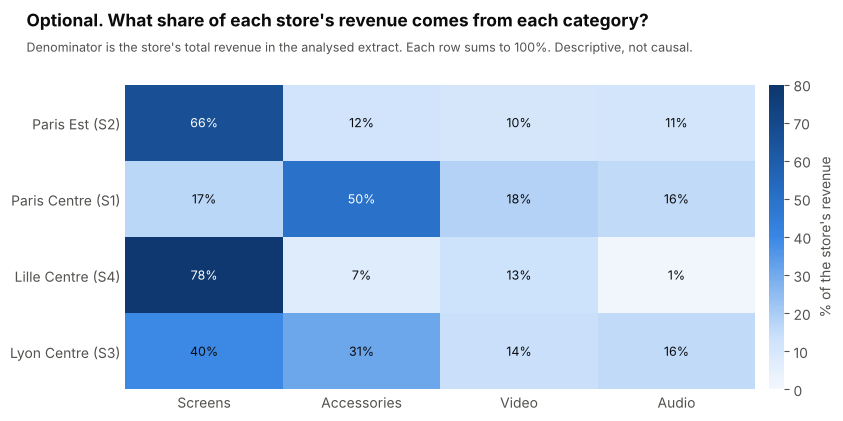

Share of each store's orders by category in % (denominator is the store's order count)


category_label,Screens,Accessories,Video,Audio
store_id,,,,
S2,30.00,34.30,15.70,20.00
S1,3.30,78.00,8.80,9.90
S4,50.00,23.30,23.30,3.30
S3,12.00,62.00,12.00,14.00


In [34]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list('one_hue_blue', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5',
                                                           '#256abf', '#184f95', '#0d366b'])
heat = mix_share.loc[store_order]
vmax = float(np.ceil(heat.to_numpy().max() / 10) * 10)

fig4, ax = plt.subplots(figsize=(1.35 * heat.shape[1] + 3.2, 0.62 * heat.shape[0] + 1.9))
im = ax.imshow(heat.to_numpy(), cmap=blues, vmin=0, vmax=vmax, aspect='auto')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=9,
                color='white' if v > 0.55 * vmax else INK)
ax.set_xticks(np.arange(heat.shape[1]))
ax.set_xticklabels(heat.columns, rotation=0)
ax.set_yticks(np.arange(heat.shape[0]))
ax.set_yticklabels([STORE_LABEL[s] for s in heat.index])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig4.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("% of the store's revenue", color=INK_2)
cbar.outline.set_visible(False)
add_titles(fig4, "Optional. What share of each store's revenue comes from each category?",
           "Denominator is the store's total revenue in the analysed extract. Each row sums to 100%. "
           'Descriptive, not causal.', top_inches=0.85)
plt.show()

order_mix = (analysis.pivot_table(index='store_id', columns='category_label', values='order_id',
                                  aggfunc='count', fill_value=0).reindex(store_order))
order_mix = (100 * order_mix.div(order_mix.sum(axis=1), axis=0))[heat.columns]
print("Share of each store's orders by category in % (denominator is the store's order count)")
display(order_mix.round(1))

fig4.savefig(OUT_DIR / 'fig4_product_mix_heatmap.png', dpi=150, bbox_inches='tight', facecolor='white')
(mix_share.loc[store_order].round(2).reset_index()
 .to_csv(OUT_DIR / 'store_category_revenue_share.csv', index=False))

**Interprétation du mix produit.** Le dénominateur est le chiffre d'affaires total de chaque magasin dans l'extrait analysé, donc chaque ligne de la carte fait 100 %. Le mix aide à expliquer les écarts de montant par commande. Les écrans représentent 78 % du chiffre d'affaires de Lille Centre et 66 % de celui de Paris Est, contre 17 % à Paris Centre, où 78 % des commandes portent sur des accessoires. Comme le nombre d'unités par commande est presque le même partout (environ 1,7), c'est surtout le prix des produits vendus qui fait monter ou baisser le montant moyen. C'est une description et non une preuve de cause, car les données ne disent pas pourquoi certains magasins vendent plus d'écrans (offre en rayon, type de clientèle ou simple couverture de l'extrait).